# Quanto custa fechar a porta? — the project end to end

**Out of Sample · 7º Datathon de Moedas Digitais FGV EESP · story notebook (deck prototype), 2 Nov 2026**

This notebook tells the whole project in the order of the future deck. Each section is one slide: a plain-English
explanation, the number or chart that carries it, and the finding file (`findings/F-0xx`) where the evidence and the
command that reproduces it live. Suggested slide titles are in Portuguese, since the deck is in pt-BR.

Data are frozen at 30 Oct 2026. Every number here is read from `data/processed/` or `results/`. Nothing is typed in by
hand, except where a finding is cited.

**How to read the numbers.** The *premium* is how much more a Brazilian pays for one digital dollar (USDT) than for one
official dollar (PTAX), in basis points (1 bp = 0.01%; 100 bps = 1%). On US$ 100,000, 1 bp ≈ R$ 54.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, TAB, FIG = ROOT / "data/processed", ROOT / "results/tables", ROOT / "results/figures"
BLUE, ORANGE, AQUA, INK, INK2, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#1f1e1c", "#52514e", "#b9b8b2", "#e4e3df"
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.color": GRID, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "axes.titleweight": "bold",
                     "legend.frameon": False, "font.size": 10})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
d = pd.read_csv(PROC / "P1-02_premium_daily.csv", parse_dates=["date_brt"], index_col="date_brt")
prem = d.premium_bps
print(f"{len(prem)} PTAX days, {prem.index[0].date()} to {prem.index[-1].date()}")

1520 PTAX days, 2020-10-13 to 2026-10-30


## 1. The question · *slide: "Quanto custa fechar a porta?"*

**Thesis (limits to arbitrage).** A price stays at parity only while some channel lets traders buy cheap on one side and
sell dear on the other. When a rule closes or taxes that channel, the price is free to drift. In Brazil, the digital
dollar (USDT bought with reais) and the official dollar (PTAX) are kept together by arbitrage between the crypto market
and the official FX market. Close the door between them and USDT should become more expensive.

**Question.** How much more did Brazilians pay for a digital dollar when a rule closed one of those doors, and which rules
mattered?

**The natural experiment.** On 23 Jun 2026 the Banco Central reportedly told banks, FX brokers, crypto firms and funds that
FX operations by funds to import virtual assets were irregular, and ordered them stopped. It was a supervisory notice,
not a published regulation. This was the closing of a door, with a date.

## 2. Hypotheses, fixed before the tests · *slide: "O que esperávamos"*

From the plan (`docs/02-dolar-cripto.md` §5), written before the confirmatory tests:

| | Hypothesis | What would support it |
|---|---|---|
| **H1** | Closing the channel (23 Jun 2026) raised the premium | A jump at that date, larger than on ordinary dates, absent in comparison currencies |
| **H2** | Only rules that close the *cheapest* channel matter | Other dated rules (licensing, reporting, eFX) show no jump |
| **H3** | The May 2025 IOF increase on official FX raised the premium by less than the tax change | A small or null move in May 2025 |
| **H0** | Nothing special: the real, USDT's own dollar price or one exchange explain the moves | The jump disappears on other exchanges or after those controls |

## 3. What we measure · *slide: "Dados e medida"*

**Premium = price of USDT in reais ÷ (PTAX × price of USDT in dollars) − 1.**
- **The two prices are matched in time.** USDT/BRL is taken from Binance in the same hours the BCB samples for PTAX (P1-02).
- **USDT's own dollar price is corrected for**, so we measure the real-vs-dollar gap, not doubts about Tether (F-004, F-006).
- **Sources:** Binance public archives (hourly, Oct 2020 – Oct 2026); BCB PTAX API; Coinbase and Bitstamp USDT/USD; Foxbit
  and Mercado Bitcoin as second and third exchanges; ECB, Superfinanciera, NBU and BCRA official rates for nine other
  currencies. All raw files are frozen with checksums (`data/README.md`, `docs/sources.md`).
- **Noise floor.** Trading friction alone (the bid-ask spread) is 2–10 bps (F-007). Anything smaller is noise.

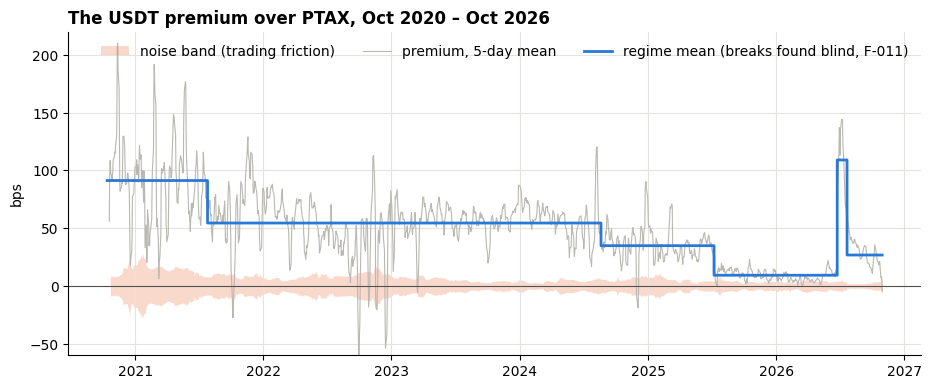

first_day_new_regime  mean_before_bps  mean_after_bps  change_bps
          2021-07-26             91.3            54.5       -36.8
          2024-08-20             54.5            34.9       -19.6
          2025-07-08             34.9             9.3       -25.6
          2026-06-24              9.3           109.1        99.8
          2026-07-22            109.1            26.8       -82.4


In [2]:
br = pd.read_csv(TAB / "P2-02_breaks.csv"); br = br[br.series == "premium_bps"]
n = pd.read_csv(PROC / "P2-01_noise_floor_daily.csv", parse_dates=["date_utc"], index_col="date_utc").noise_band_bps.reindex(prem.index)
starts = [prem.index[0]] + list(pd.to_datetime(br.first_day_new_regime)); means = [br.mean_before_bps.iloc[0]] + list(br.mean_after_bps)
level = pd.Series(np.nan, index=prem.index)
for a, z, m in zip(starts, starts[1:] + [prem.index[-1] + pd.Timedelta(days=1)], means):
    level[(prem.index >= a) & (prem.index < z)] = m
fig, ax = plt.subplots()
ax.fill_between(n.index, -n, n, color=ORANGE, alpha=.25, lw=0, label="noise band (trading friction)")
ax.plot(prem.index, prem.rolling(5).mean(), color=MUTED, lw=.8, label="premium, 5-day mean")
ax.plot(level.index, level, color=BLUE, lw=2, drawstyle="steps-post", label="regime mean (breaks found blind, F-011)")
ax.axhline(0, color=INK2, lw=.8); ax.set_ylim(-60, 220); ax.set_ylabel("bps")
ax.set_title("The USDT premium over PTAX, Oct 2020 – Oct 2026"); ax.legend(loc="upper right", ncol=3); plt.show()
print(br[["first_day_new_regime", "mean_before_bps", "mean_after_bps", "change_bps"]].to_string(index=False))

**What it shows.**
- **The premium is real and well above trading noise:** 4–11× the spread in every year (F-001, F-007).
- **It fell steadily** from about 91 bps (2020–21) to about 9 bps (mid-2025 – Jun 2026) as the market deepened.
- **24 Jun 2026 is the sharpest change in six years: +100 bps.** A break test that was given *no dates* finds it on its
  own (F-011). The premium falls back from 22 Jul.

## 4. The jump of 24 June · *slide: "O salto: mesmo tamanho em três corretoras"*

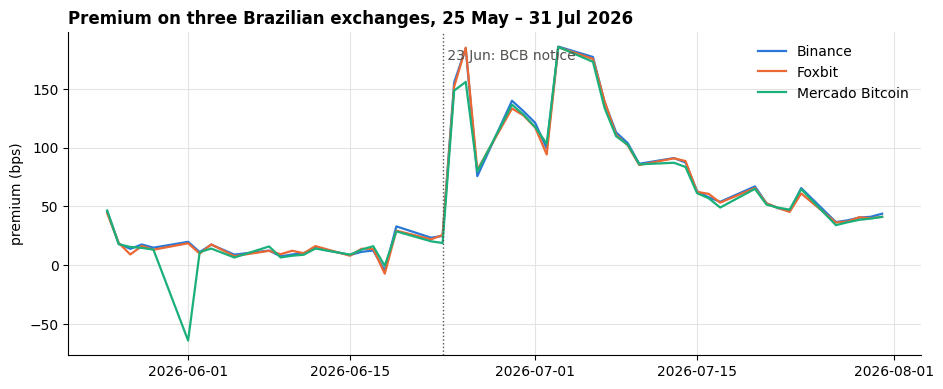

20 days before → 20 days after (bps):
                 before  after  change
Binance            15.2  109.1    93.9
Foxbit             14.7  108.0    93.3
Mercado Bitcoin    10.7  105.6    94.9


In [3]:
v = pd.read_csv(TAB / "P2-05_venues_daily.csv", parse_dates=["date_brt"], index_col="date_brt")
fig, ax = plt.subplots()
for c, col in zip(v.columns, [BLUE, ORANGE, AQUA]):
    ax.plot(v.index, v[c], color=col, lw=1.6, label=c)
ax.axvline(pd.Timestamp("2026-06-23"), color=INK2, ls=":", lw=1); ax.text(pd.Timestamp("2026-06-23"), 175, " 23 Jun: BCB notice", color=INK2)
ax.set_ylabel("premium (bps)"); ax.set_title("Premium on three Brazilian exchanges, 25 May – 31 Jul 2026"); ax.legend(); plt.show()
pre, post = v.loc[:"2026-06-22"].tail(20), v.loc["2026-06-24":].head(20)
print("20 days before → 20 days after (bps):"); print((pd.DataFrame({"before": pre.mean(), "after": post.mean(), "change": post.mean() - pre.mean()})).round(1))

**What it shows.**
- **The same jump on three independent order books:** +93 to +95 bps on Binance, Foxbit and Mercado Bitcoin. It is not
  one exchange's problem (H0 rejected for "one venue").
- **Other explanations ruled out (F-009):**
  - the real moved +0.68% that day, an ordinary move;
  - USDT's own dollar price moved less than 1 bp;
  - nothing happened at Binance itself.
- **Timing.** Hour by hour, the rise starts in the afternoon of 23 Jun, with a second step at the 24 Jun open. One
  account says the notice became public "the next day".

## 5. What we know about the notice · *slide: "A porta que fechou"*

| Source | What it says | Weight |
|---|---|---|
| Isac Costa, ConJur, 1 Jul 2026 | BCB notice of 23 Jun to banks, brokers and funds; FX imports of virtual assets via funds irregular | opinion column by a former CVM analyst |
| Sérgio Brotto (CEO, Dascam FX broker), Cointelegraph Brasil, 6 Jul 2026 | same notice; "ilegalidade… imediata descontinuidade"; "tornou-se pública no dia seguinte" | opinion piece, independent of the first |
| Webitcoin, 30 Jul 2026, on the BCB's answer to a freedom-of-information request | fund FX operations to import virtual assets "não possuem respaldo nas normas" | the BCB's own position, no date given |

**Honest status.**
- We have **two independent accounts** of the notice and the **BCB's position in its own words**. We have **not seen the
  notice itself**; it was not published in the official gazette.
- So the deck should say: the jump *coincides with* a reported supervisory notice. It should not say "the BCB caused".

## 6. Every dated rule against ordinary days · *slide: "Só uma regra mexeu no preço"*

**The test.**
- **For each rule** in our verified list (13 events), compare the premium in the 20 days before and the 20 days after.
- **Placebo dates.** To know what "a big change" means, we do the same for every ordinary date, at least 20 days away
  from any event. If a rule's change is bigger than almost every ordinary date's, it is unusual.

event_id eval_date_kind event_date  pre_mean_bps  post_mean_bps  diff_bps  p (vs all ordinary dates)
    E-01   announcement 2025-05-22         26.91          40.09     13.18                     0.3845
    E-01      effective 2025-05-23         26.21          41.65     15.44                     0.3147
   E-01b   announcement 2025-06-27         39.92          16.00    -23.92                     0.1648
   E-01b      effective 2025-07-04         37.57          12.69    -24.88                     0.1527
    E-02   announcement 2025-11-10         13.25           9.46     -3.79                     0.7477
    E-02      effective 2026-02-02          8.43           4.12     -4.31                     0.7225
    E-03   announcement 2026-02-05          7.63           5.51     -2.11                     0.8408
    E-04   announcement 2025-11-10         13.25           9.46     -3.79                     0.7477
    E-04      effective 2026-05-04          4.65          11.89      7.24                  

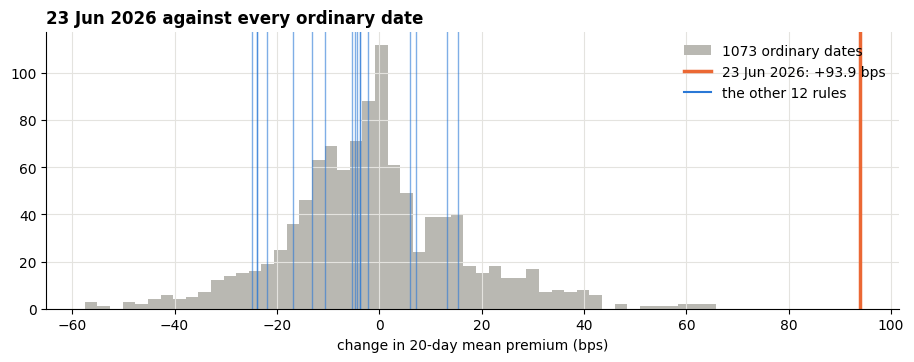

Largest ordinary-date change: +65.7 bps. 95% of ordinary dates move less than ±37 bps (±23 bps in 2025–26).


In [4]:
ev = pd.read_csv(TAB / "P2-03_event_table.csv"); ev = ev[ev.status == "evaluated"]
show = ev[["event_id", "eval_date_kind", "event_date", "pre_mean_bps", "post_mean_bps", "diff_bps", "p_placebo_all_clean_2s"]]
print(show.rename(columns={"p_placebo_all_clean_2s": "p (vs all ordinary dates)"}).to_string(index=False))
events = pd.read_csv(PROC / "P1-04_events_brazil.csv"); pos = set()
for col in ["date_announced", "date_effective"]:
    for x in events[col].astype(str):
        if x not in ("N/A", "nan"):
            after = prem.index[prem.index >= pd.Timestamp(x)]
            if len(after): pos.add(prem.index.get_loc(after[0]))
black = {q for e in pos for q in range(e - 20, e + 21)}
clean = [i for i in range(20, len(prem) - 20) if i not in black]
diffs = np.array([prem.iloc[i + 1:i + 21].mean() - prem.iloc[i - 20:i].mean() for i in clean])
e05 = ev[ev.event_id == "E-05"].diff_bps.iloc[0]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.hist(diffs, bins=50, color=MUTED, label=f"{len(diffs)} ordinary dates")
ax.axvline(e05, color=ORANGE, lw=2.5, label=f"23 Jun 2026: {e05:+.1f} bps")
for x in ev[ev.event_id != "E-05"].diff_bps: ax.axvline(x, color=BLUE, lw=1, alpha=.6)
ax.plot([], [], color=BLUE, label="the other 12 rules"); ax.set_xlabel("change in 20-day mean premium (bps)")
ax.set_title("23 Jun 2026 against every ordinary date"); ax.legend(); plt.show()
mde_all, mde_recent = np.quantile(abs(diffs), .95), np.quantile(abs(diffs[[prem.index[i].year >= 2025 for i in clean]]), .95)
print(f"Largest ordinary-date change: {diffs.max():+.1f} bps. 95% of ordinary dates move less than ±{mde_all:.0f} bps "
      f"(±{mde_recent:.0f} bps in 2025–26).")

**What it shows.**
- **23 Jun 2026 is beyond every one of the 1,073 ordinary dates** (+93.9 bps vs at most +66; p ≈ 0.001) (F-016).
- **No other rule stands out (H2 consistent).** That includes the virtual-asset licensing framework (Res. 519–521), the
  reporting codes, the eFX rule and the 3.5% crypto-IOF proposal. Their changes are −25 to +15 bps, inside ordinary
  variation.
- **The May 2025 IOF increase on official FX** moved the premium by +13 to +15 bps, which is not unusual (H3 consistent).
- **Read the nulls carefully.** This test cannot see moves smaller than about ±37 bps (±23 bps in calm 2025–26), because
  ordinary dates move that much. "No effect" means "no *large* effect".

## 7. Brazil against a "synthetic Brazil" · *slide: "Outros países não se mexeram"*

**The test.**
- **Synthetic Brazil.** The same premium measured for other currencies with no comparable shock (euro, Turkish lira, rand,
  Mexican peso, Colombian peso), combined into a "synthetic Brazil" that tracked Brazil before June.
- **The question.** After 23 Jun, did Brazil leave its synthetic twin? A simpler check, "Brazil minus the average of
  the others" (difference-in-differences), needs no fitting.

                             specification  pre_rmspe_bps  acute_gap_sc_bps  plateau_gap_sc_bps  did_acute_gap_bps placebo_rank  permutation_p_value
                        5-donor (Headline)           7.05            109.31               28.16             103.34          1/6                0.167
                   5-donor (BRL_ecb check)          16.58            101.57               32.32              96.83          1/6                0.167
                   Strict 4-donor (ex-EUR)          10.33            116.69               33.94             102.90          1/5                0.200
         Strict 4-donor (ex-EUR) [BRL_ecb]          18.25            108.54               37.72              96.44          1/5                0.200
          6-donor (with IDR from Dec 2025)           7.19            109.87               28.58             104.74          1/7                0.143
6-donor (with IDR from Dec 2025) [BRL_ecb]          16.90            102.10               32.61           

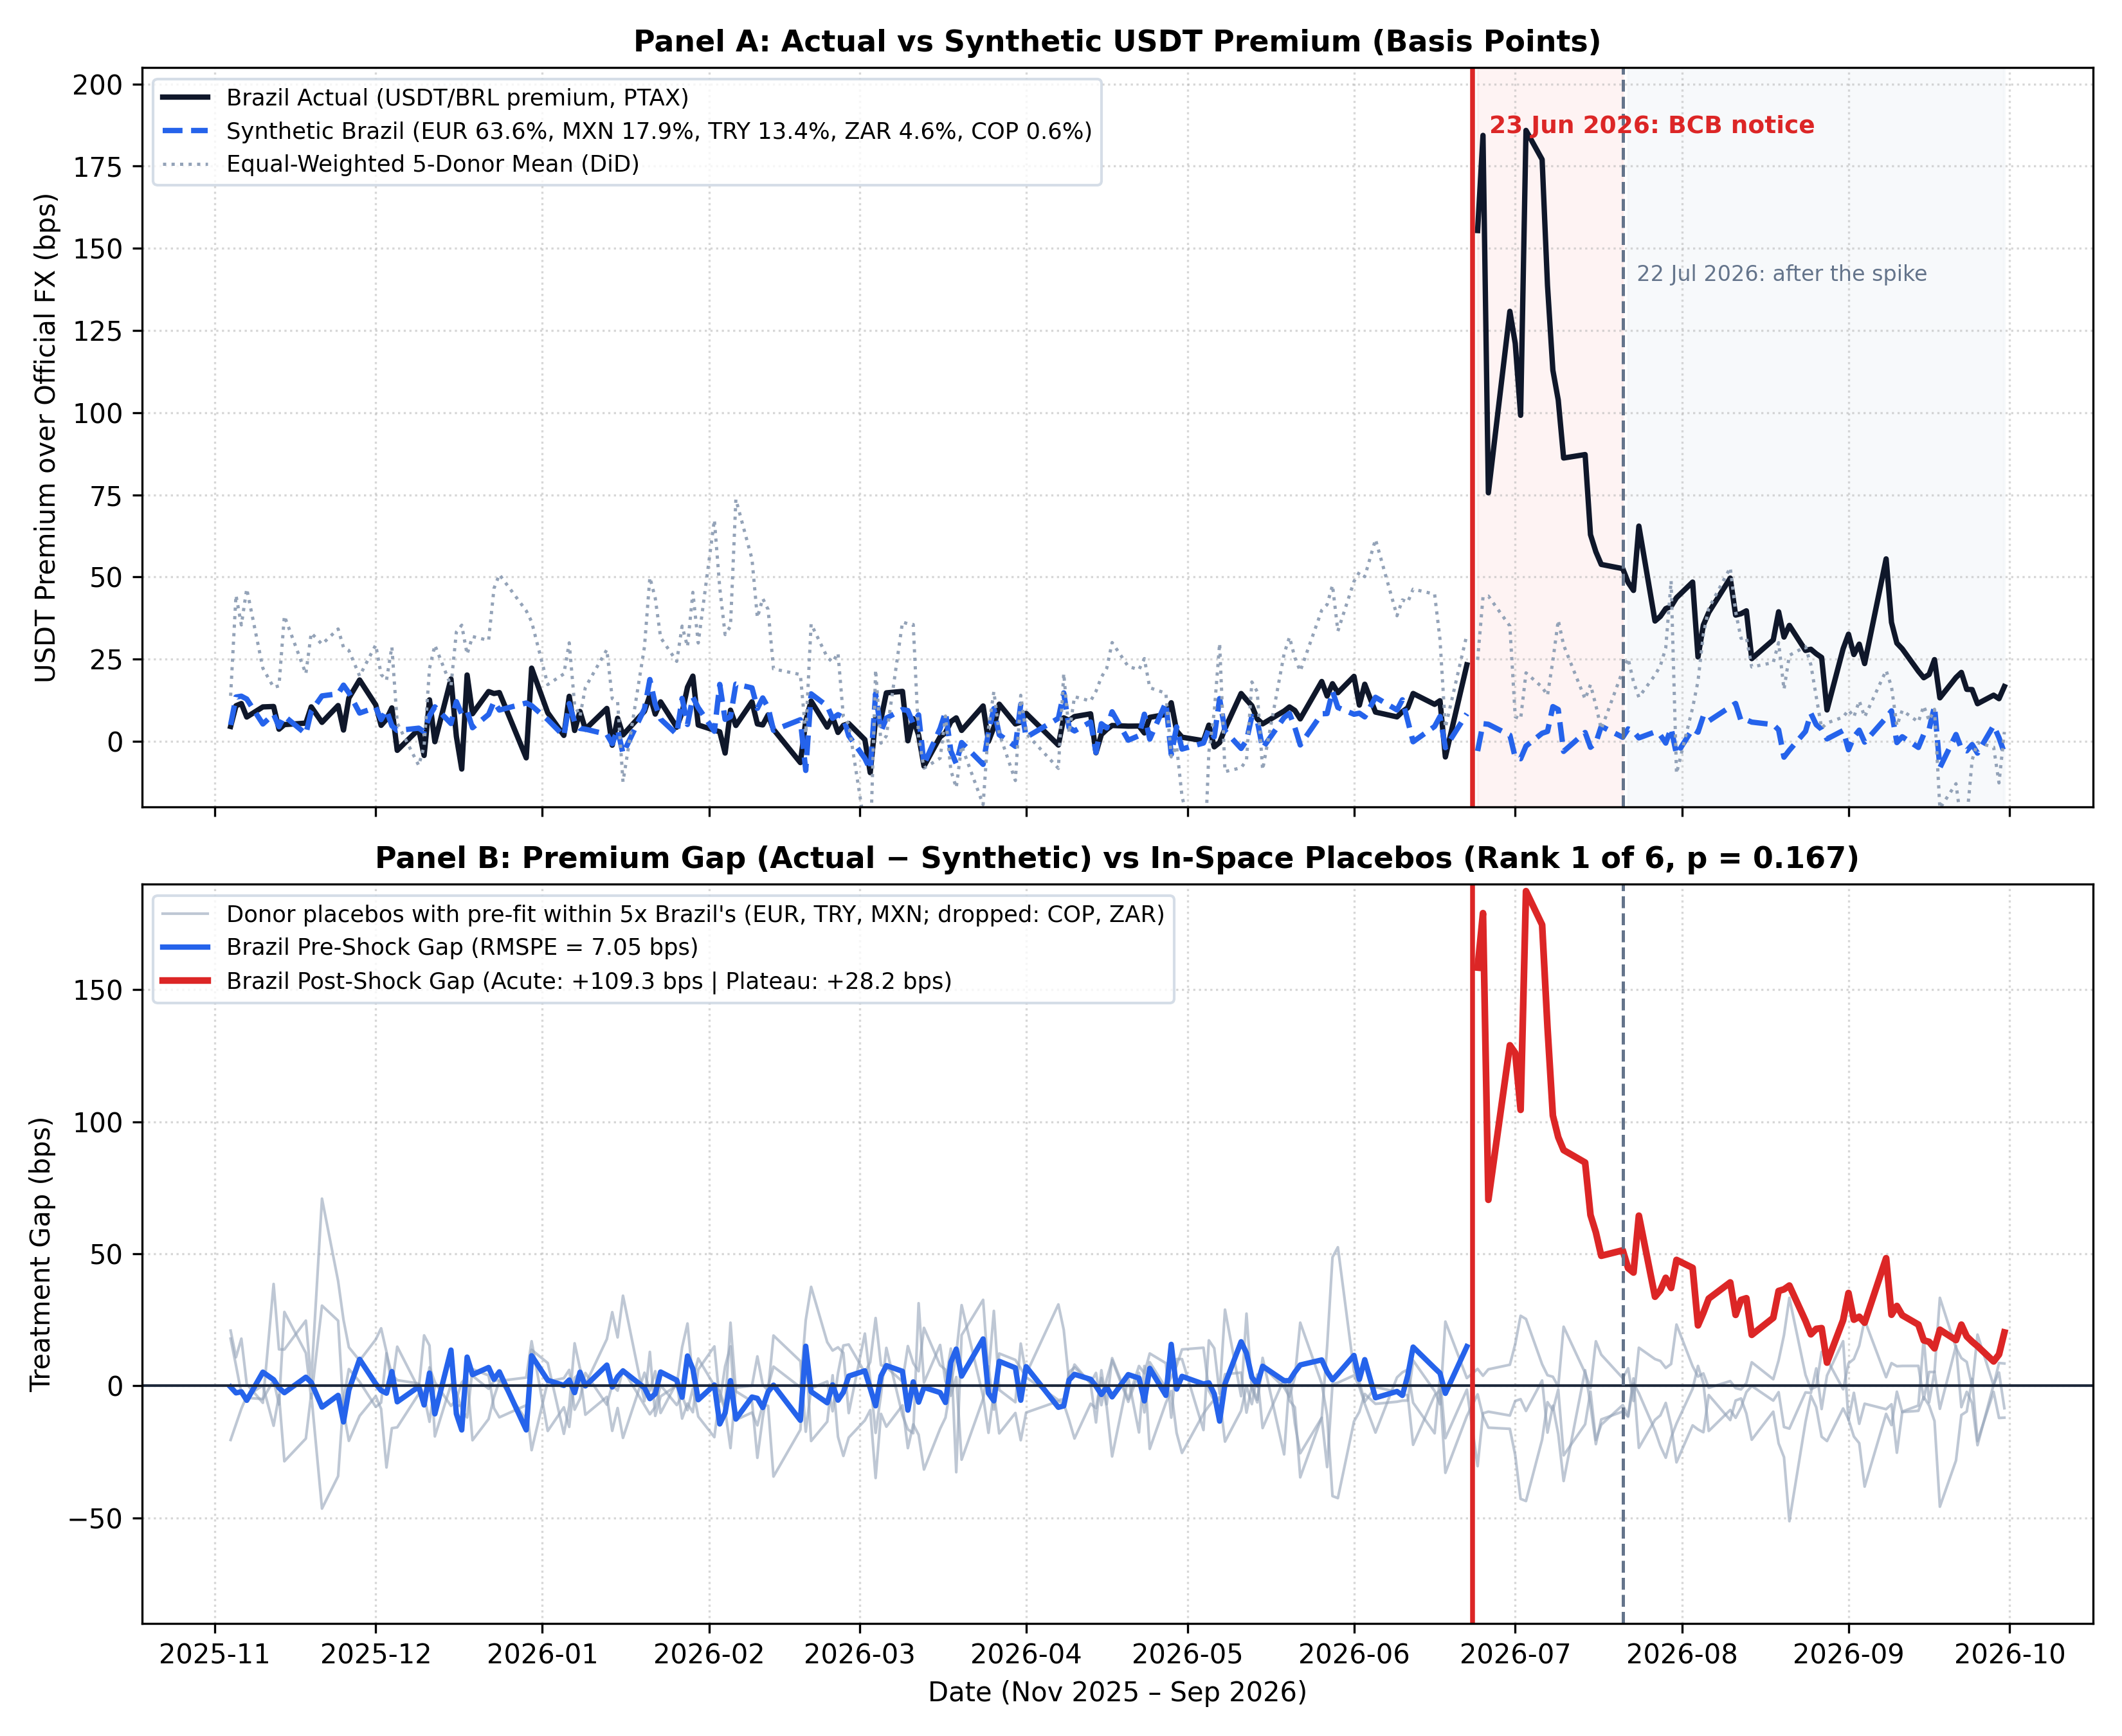

In [5]:
sc = pd.read_csv(TAB / "P2-04_synth_results.csv")
print(sc[["specification", "pre_rmspe_bps", "acute_gap_sc_bps", "plateau_gap_sc_bps", "did_acute_gap_bps", "placebo_rank", "permutation_p_value"]].to_string(index=False))
display(Image(FIG / "P2-04_synthetic_control.png", width=900))

**What it shows.**
- **Brazil left its twin by about +109 bps during the spike**, +103 bps against the simple average. No other currency moved
  like that: their changes were −16 to +24 bps (F-017). A global crypto or emerging-market shock does not explain the jump.
- **Limit.** With only 5 comparison currencies, Brazil ranking first gives p = 1/6 ≈ 0.17. This is supporting evidence;
  the significance comes from section 6. Binance has no other fiat pair covering the period.

## 8. A spike, not a new level · *slide: "Um pico de um mês"*

In [6]:
rb = pd.read_csv(TAB / "P4-01_robustness.csv")
acute = rb[rb.type == "acute"]; plate = rb[rb.specification.str.contains("after-spike level vs placebo")]
print(f"Spike: {len(acute)} variants (windows, premium definitions, exchanges, synthetic control, DiD) give "
      f"{acute.effect_or_gap_bps.min():+.1f} to {acute.effect_or_gap_bps.max():+.1f} bps.")
print(plate[["specification", "effect_or_gap_bps", "se_or_ci", "p_value_or_rank"]].to_string(index=False))
i = prem.index.get_loc(pd.Timestamp("2026-06-23"))
print(f"Before (25 May – 22 Jun): {prem.iloc[i-20:i].mean():.1f} bps · spike (24 Jun – 21 Jul): {prem.iloc[i+1:i+21].mean():.1f} · "
      f"after (22 Jul – 30 Oct): {prem.iloc[i+21:].mean():.1f}")

Spike: 26 variants (windows, premium definitions, exchanges, synthetic control, DiD) give +73.7 to +128.3 bps.
                                                        specification  effect_or_gap_bps                      se_or_ci   p_value_or_rank
      [+21, +60] after-spike level vs placebo dates (all clean dates)              19.31 placebo sd 16.5 bps (n = 882) p_placebo = 0.239
[+21, +60] after-spike level vs placebo dates (clean dates from 2025)              19.31   placebo sd 8.1 bps (n = 85) p_placebo = 0.140
Before (25 May – 22 Jun): 15.2 bps · spike (24 Jun – 21 Jul): 109.1 · after (22 Jul – 30 Oct): 26.8


**What it shows.**
- **The spike is robust.** Every way we measured it gives +74 to +128 bps (F-022).
- **It lasted about a month.** The premium went from 15 to 109 bps, then from 22 Jul back to about 27 bps.
- **What remained (+11 to +19 bps) is *not* distinguishable from ordinary drift:** ordinary dates move that much often
  (p = 0.24). So the measured effect of closing the door is **a one-month spike**. We cannot claim a lasting new price
  level.
- **Two things we cannot explain yet:**
  - **The fade.** Nothing in our verified event list falls within 5 days of 22 Jul (P2-02).
  - **The build-up.** The premium was already drifting up from 25 May (+8 bps). The cause is unknown; it may be
    anticipation or noise.

## 9. The same mechanism across countries · *slide: "Onde a porta está fechada, o prêmio é grande"*

In [7]:
x = pd.read_csv(PROC / "P1-05_donor_premiums_daily.csv", parse_dates=["date"], index_col="date")[:"2026-06-22"]
t = x.groupby(x.index.year).mean().loc[2024:].T.round(0)
t.columns = [f"mean {c} (bps)" for c in t.columns]; print(t.to_string())

          mean 2024 (bps)  mean 2025 (bps)  mean 2026 (bps)
BRL_ptax             49.0             22.0              8.0
EUR                   7.0              1.0              1.0
TRY                  51.0              1.0             -7.0
ZAR                 196.0             97.0             68.0
MXN                  72.0             36.0             17.0
PLN                  36.0              9.0             12.0
IDR                   NaN             33.0             19.0
BRL_ecb              56.0             25.0             12.0
COP                -217.0            -69.0             22.0
UAH                 853.0            490.0            412.0
ARS                3037.0            721.0            548.0


**What it shows (description, not a test).**
- **Where residents cannot buy dollars freely, USDT costs 4–7% more** than the official dollar: Argentina (7.2% in 2025,
  5.5% in 2026) and Ukraine under martial-law controls (4.1–4.9%).
- **In open markets it is within about 1%:** euro, Mexico, Colombia, Turkey in 2025–26 (F-010).
- **Brazil sits at the open end**, and moved toward the closed end for one month after 23 Jun.
- Two controlled currencies are too few for a test.

## 10. What the notice cost · *slide: "Quanto custou: R$ 5 mil por US$ 100 mil"*

In [8]:
rc = pd.read_csv(TAB / "P3-01_route_costs.csv")
print(rc[rc.category == "Cost of the notice"][["regime_or_scenario", "premium_bps", "cost_usd_per_100k", "cost_brl_per_100k", "notes"]].to_string(index=False))

                                        regime_or_scenario  premium_bps  cost_usd_per_100k  cost_brl_per_100k                                                                                    notes
          Cost of the notice: spike (24 Jun - 21 Jul 2026)         93.9             939.10            5052.36               Premium change after E-05, [+1,+20] vs [-20,-1] (F-016); placebo p ~ 0.001
Cost of the notice: after the spike (22 Jul - 30 Oct 2026)         11.5             115.43             621.00 [+21,end] vs [-20,-1]; NOT distinguishable from ordinary drift (placebo p = 0.24, F-022)


**What it shows.**
- **For someone buying US$ 100,000 in USDT, the notice added about US$ 940 ≈ R$ 5,050** during the month of the spike.
  After the spike, about R$ 620, which, as section 8 showed, we cannot tell apart from noise (F-015).
- **Why the bank-route comparison stays out of the headline.** The table in `P3-01_route_costs.csv` also compares USDT with
  bank FX routes. That comparison depends on the IOF and on an *assumed* bank spread. Presented as "savings", it reads like
  a way around a tax, which is the very practice the notice reportedly targets. The team still has to decide whether it
  appears at all (framing rule, `prompt.md` §10).

## 11. The same mechanism in dollars: the SVB weekend · *slide: "Do lado do dólar: quando o resgate fecha"*

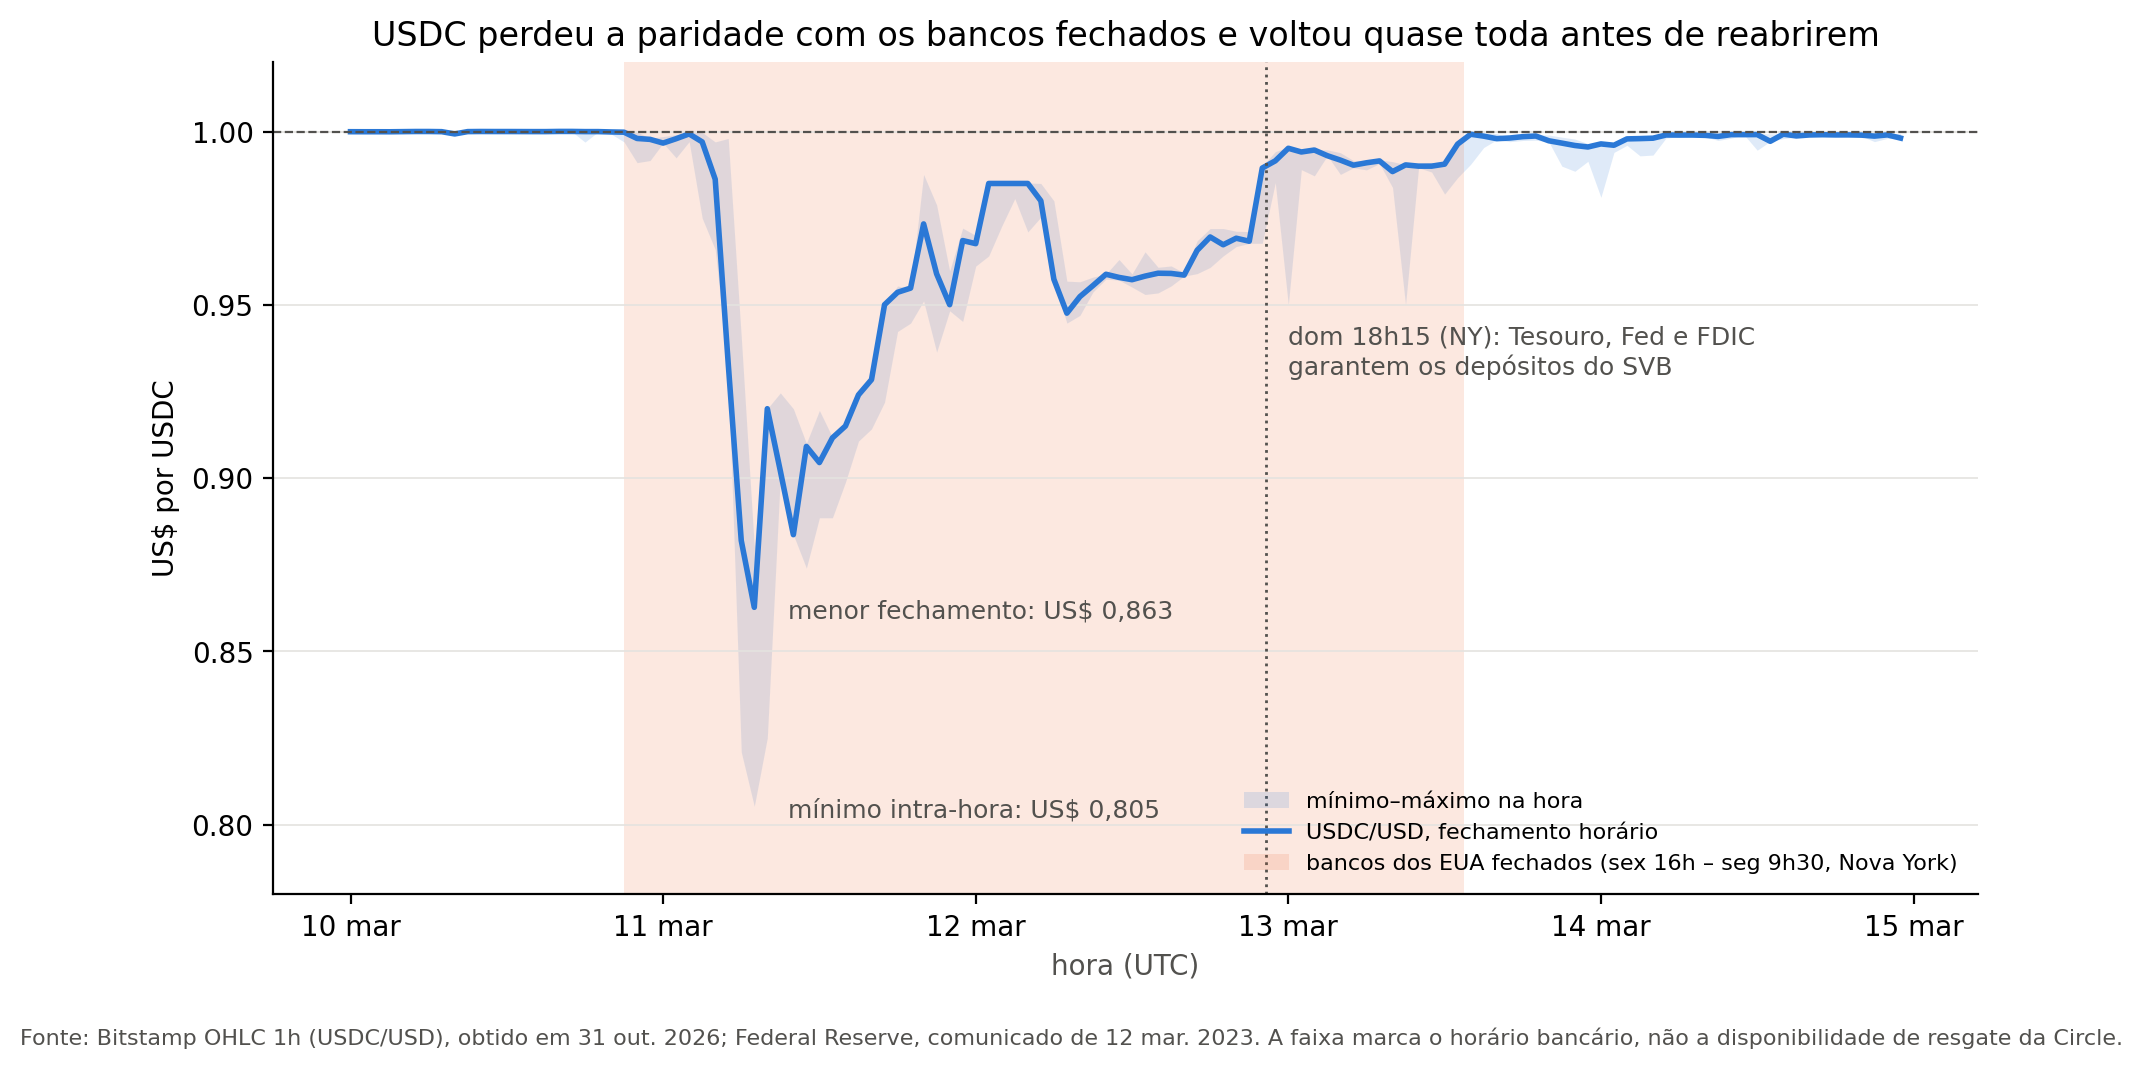

Screen of 7 stablecoins on Binance, 2019–2026: 24 episodes outside ±0.5% confirmed in dollars; 11 below $1, 13 above $1 (F-013).


In [9]:
display(Image(FIG / "P1-07_svb_weekend_v2.png", width=900))
e2 = pd.read_csv(PROC / "P1-07_depeg_events_v2.csv"); ok = e2[e2.classification == "USD-confirmed"]
print(f"Screen of 7 stablecoins on Binance, 2019–2026: {len(ok)} episodes outside ±0.5% confirmed in dollars; "
      f"{(ok.direction == 'below').sum()} below $1, {(ok.direction == 'above').sum()} above $1 (F-013).")

**What it shows.**
- **USDC lost its peg while the redemption channel was closed.** Circle could not pay out dollars over the weekend banks
  were shut. USDC's lowest hourly close was $0.863.
- **It returned to $0.989 within an hour of the Sunday deposit guarantee** (22:15 UTC), *before* banks reopened. What
  restored parity was credible access to the dollar again.
- **The parallel to Brazil:** when the channel that enforces parity closes, the price leaves parity; when it is credibly
  reopened, the price returns.
- **Our screen finds only 11 independent falls below $1** in seven coins. That is too few for survival curves (our rule
  needs 12), so the chapter is a case table (F-019).

## 12. The solution: a daily monitor · *slide: "Monitor do Dólar Digital"*

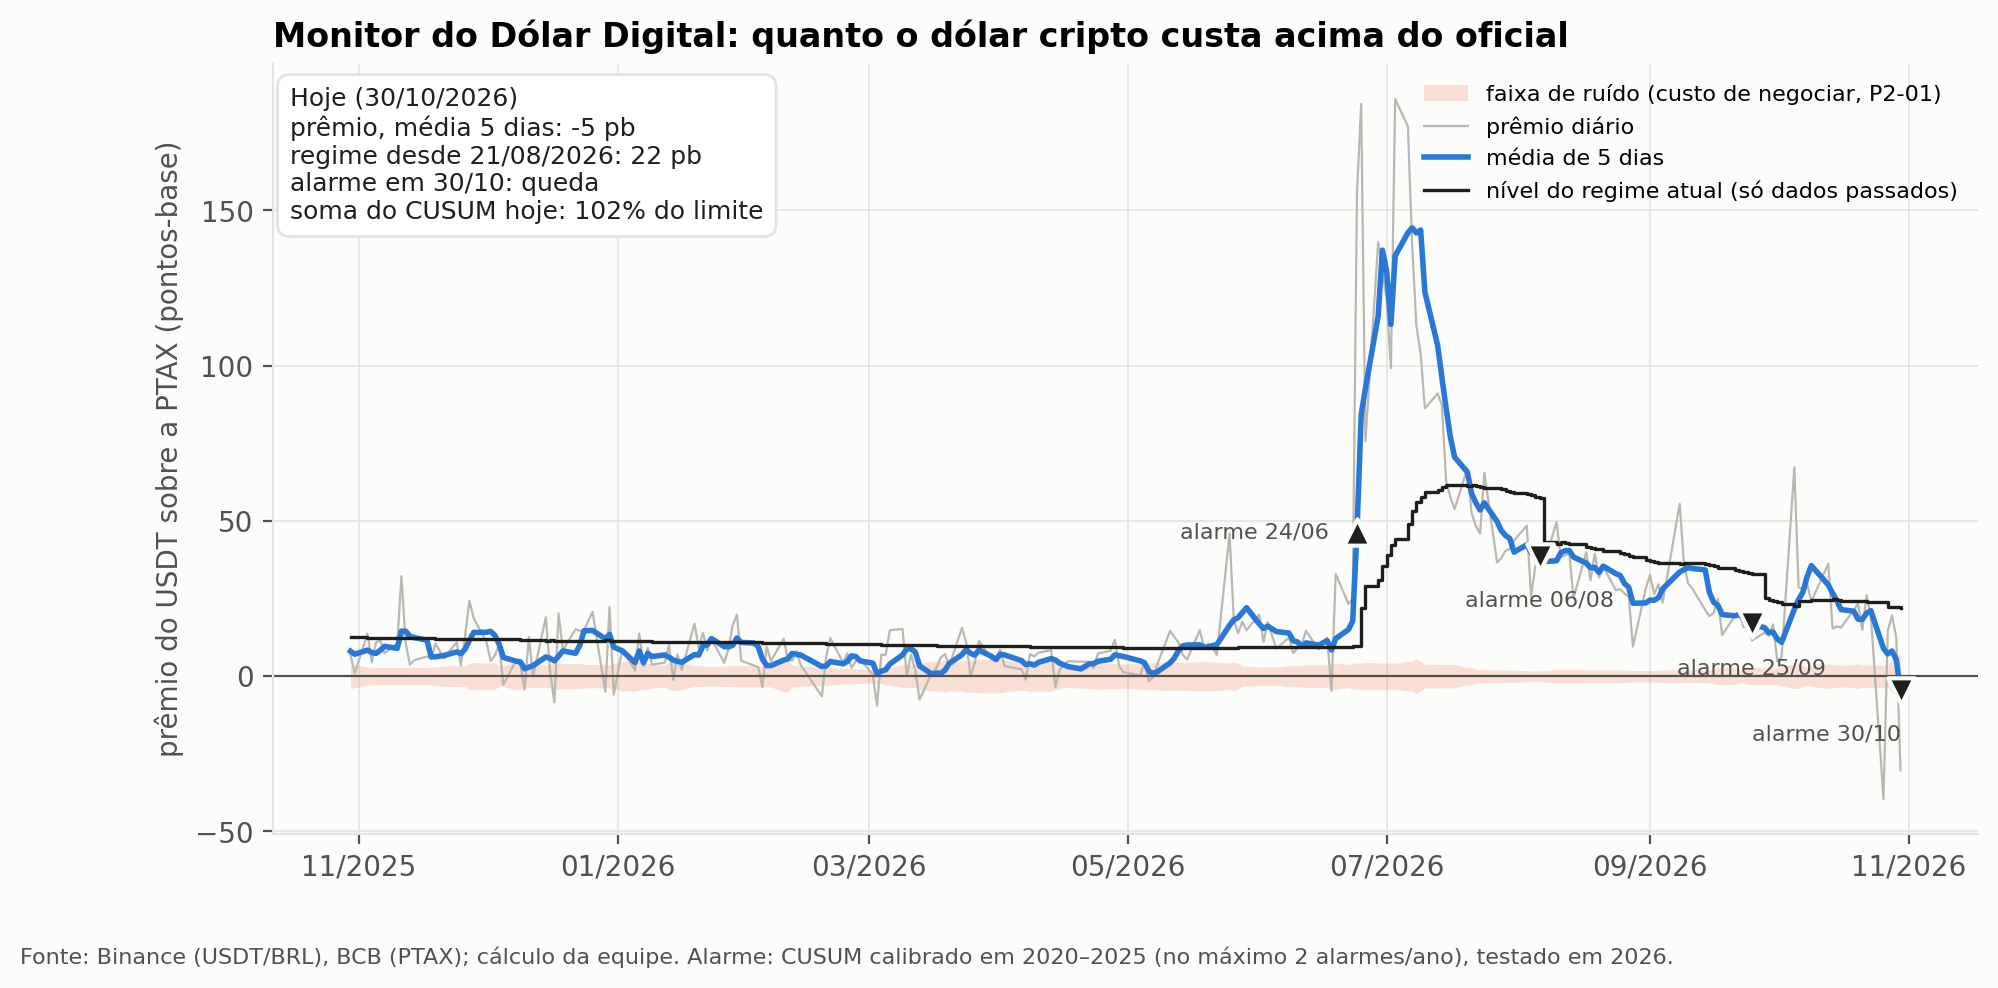

rule                                                       CUSUM                    simple (5d vs 60d mean, x noise band)
parameter                                               h = 24.5                                                 c = 7.25
alarm budget in training                                      10                                                       10
jump 24 Jun 2026: alarm                               2026-06-24                                               2026-06-24
jump 24 Jun 2026: delay (PTAX days)                            0                                                        0
fade 22 Jul 2026: alarm                               2026-08-06                                               2026-08-07
fade 22 Jul 2026: delay (PTAX days)                           11                                                       12
train alarms                                                   9                                                       10
test alarms             

In [10]:
display(Image(FIG / "P3-03_monitor.png", width=900))
print(pd.read_csv(TAB / "P3-03_backtest.csv").set_index("rule").T.to_string())

**What it shows.**
- **A rule that uses only past data, set on 2020–2025 and tested on 2026, flags the 24 Jun jump the same day** (F-014).
- **It is quieter than a naive rule:** 2 other alarms in 2026 vs 4 for a simple "5-day vs 60-day average" rule with the same
  alarm budget.
- **For a regulator or a treasurer:** a free, daily reading of how closed the door is.

## 13. Lessons from 2025 · *slide: "Lições de 2025"*

| 2025 (3rd place) | 2026 |
|---|---|
| Best model lost to "tomorrow = today" (F-005) | Every estimate shown next to its naive baseline; the monitor beats a simple rule |
| Causal language from clustering | Causal claims only from designs with placebos (event study, synthetic control), and only for the spike |
| Brazil only in the introduction | Brazil is the question |
| Tuned freely | Hypotheses and test specifications written and committed before running (git history shows the order) |

## 14. Scorecard · *slide: "O que os testes mostraram"*

| Hypothesis | Verdict | Evidence |
|---|---|---|
| **H1** closing the channel raised the premium | **Supported for a one-month spike** (+94 bps, p ≈ 0.001; same on 3 exchanges; no other currency moved). **Not shown** for a lasting effect (p = 0.24) | F-009, F-011, F-016, F-017, F-022 |
| **H2** only the binding rule matters | **Consistent**: no other rule moved more than ordinary dates. The test only sees moves above ~25–37 bps | F-016 |
| **H3** IOF May 2025 moved the premium less than the tax | **Consistent** (+13 to +15 bps, not unusual) | F-016 |
| **H0** venue, real or USDT explain it | **Rejected** for the 24 Jun jump | F-009 |

## 15. Limits we must say on the slide · *slide: "Limitações"*
- **The notice itself is unseen.** We have two independent accounts and the BCB's stated position, not the document.
  So: "coincides with", not "caused by".
- **Only the spike is measured.** Why it faded after a month is unexplained, and a lasting effect is not shown.
- **The premium was already drifting up from 25 May.** Cause unknown.
- **Our cross-country evidence is thin.** The synthetic control has 5 donors (p = 0.17 at best), and the cross-country
  evidence is descriptive.
- **Exchange data are Binance-centred.** Foxbit and Mercado Bitcoin confirm the jump, but the long history is Binance only.
- **The causes in the depeg cases are not yet sourced.**